Exposé computationel séance 5

Filtrage données et analyse univariée (et aussi bivariée)

- Ilona
- Max
- Morgane



- **Pourquoi et comment isoler les données qui nous intéressent pour notre analyse ?**
- **Qu'est-ce que sont les masques booléens ?**
- **Comment détecter les erreurs/anomalies statistiques ?**
- **Comment explorer les données simplement ?**
- **Pourquoi et comment faire des graphiques ?**

**I - Masques booléens**

In [ ]:
# On commence par installer panda
import pandas as pd
from google.colab import files

# On importe le fichier depuis l'ordinateur. En faisant ça, une fenetre s'ouvre en bas et demande de selectionner un fichier
uploaded = files.upload()

# On recupère  le fichier
barometre = list(uploaded.keys())[0]

# Il faut demander à panda de lire un fichier CSV en utilisant les séparation de colones adéquates (dans certaines bases de données c'est des points vigules)
df = pd.read_csv(barometre, sep=";")

# Et on peut ensuite afficher les premières lignes
display(df.head())

Saving Baromètre Sexisme HCE.csv to Baromètre Sexisme HCE (2).csv


,responseid,SEXE : SEXE - Vous êtes :,AGE_1 : AGE_1 (AGE - Veuillez nous indiquer votre âge :),REC_uda5 : REC_uda5 - Recodage en région UDA5 (question cachée),REC_REGION_NEW : REC_REGION_NEW - Recodage nouvelles régions :,REC_AGGLO_QUOTA : REC_AGGLO_QUOTA - Taille d’agglomération pour quotas,REC_TailleAgglo5 : REC_TailleAgglo5,REC_AGE3 : REC_AGE3,"ACTIVITE_REP : ACTIVITE_REP - Actuellement, quelle est votre situation principale ?",PCS_REP : PCS_REP - Dans quelle catégorie socioprofessionnelle vous situez-vous ?,...,"RELIGION : RELIGION - Aujourd’hui, pratiquez-vous une religion ?",DIPLOME : DIPLOME - Quel est le diplôme le plus élevé que vous ayez obtenu ?,FOYER : FOYER - Vous vivez... ?,REVENUS_FOYER : REVENUS_FOYER - A combien estimez-vous les revenus annuels nets de votre foyer (en euros),REF : REF - Êtes-vous la personne qui contribue le plus aux revenus de votre foyer ?,"ACTIVITE_REF : ACTIVITE_REF - Actuellement, quelle est la situation de la personne qui contribue le plus aux revenus de votre foyer ? Cette personne…",PCS_REF : PCS_REF - Dans quelle catégorie socioprofessionnelle se situe la personne qui contribue le plus aux revenus de votre foyer ?,RECODE_PCS_REF : RECODE_PCS_REF,RECODE_PCS_REF2 : RECODE_PCS_REF2,POIDS
0,3,Une femme,33,Sud-Ouest,Nouvelle-Aquitaine,Communes urbaines de province,Unité urbaine de 100 000 à 1 999 999 habitants,25-34 ans,J’exerce une activité professionnelle (salarié...,"Employé (ex. assistant administratif, secrétai...",...,Non,"Bac+3 (Licence, Bachelor, Licence professionne...",En couple avec enfant(s),De 48 000&#8364; à moins de 60 000&#8364; (4 0...,Oui,NaN,NaN,NaN,NaN,"1,04230201"
1,5,Une femme,78,Nord-Est,Grand Est,Communes urbaines de province,Unité urbaine de 2 000 à 19 999 habitants,65 ans et plus,Je suis retraité ou pré-retraité,NaN,...,Oui de temps en temps,"Supérieur à Bac+5 (Doctorat , diplôme post-mas...",En couple sans enfant,De 36 000&#8364; à moins de 48 000&#8364; (3 0...,Non,Est retraité(e) ou pré-retraité(e),NaN,Inactifs,Retraités,"0,895810025"
2,6,Un homme,43,Nord-Ouest,Bretagne,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,35-49 ans,J’exerce une activité professionnelle (salarié...,"Profession libérale et assimilée (ex. avocat, ...",...,Non,Baccalauréat d’enseignement technique ou général,Seul(e) avec enfant(s),Moins de 12 000&#8364; (soit moins de 1 000&#8...,Oui,NaN,NaN,NaN,NaN,"0,914853741"
3,8,Un homme,58,Région Parisienne,Île de France,Agglomération parisienne,Unité urbaine de Paris,50-64 ans,J’exerce une activité professionnelle (salarié...,Cadre ou profession intellectuelle et artistiq...,...,Oui de temps en temps,"Bac+5 (Master 2, diplôme d’ingénieur ou équiva...",En couple avec enfant(s),72 000&#8364; et plus (6 000&#8364; par mois...,Non,"Exerce une activité professionnelle (salarié, ...",Cadre ou profession intellectuelle et artistiq...,PCS+,Cadres et professions libérales,"1,019299207"
4,9,Un homme,44,Sud-Est,Occitanie,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,35-49 ans,J’exerce une activité professionnelle (salarié...,"Ouvrier (ex. ouvrier qualifié, ouvrier non qua...",...,Non,Certificat d’aptitude professionnelle (CAP),En couple sans enfant,De 24 000&#8364; à moins de 36 000&#8364; (2 0...,Oui,NaN,NaN,NaN,NaN,"0,965275199"


On travaille donc sur un barometre du sexisme.
 Pour commencer, on s'interressera aux masques Booléens. Ils fonctionnent comme un filtre, pour ne conserver que les modalités de reponses qui nous interressent. Par exemple, si on cherche à identifier la répartition des attitudes sexistes chez les jeunes hommes, on peut selectionner uniquement la population masculine

In [ ]:
# pour trouver le nom de nos variables, on demande à Python de toutes les lister :
print(df.columns.tolist())

['responseid', 'SEXE : SEXE - Vous êtes :', 'AGE_1 : AGE_1 (AGE - Veuillez nous indiquer votre âge :)', 'REC_uda5 : REC_uda5 - Recodage en région UDA5 (question cachée)', 'REC_REGION_NEW : REC_REGION_NEW - Recodage nouvelles\xa0régions :', 'REC_AGGLO_QUOTA : REC_AGGLO_QUOTA - Taille d’agglomération pour quotas', 'REC_TailleAgglo5 : REC_TailleAgglo5', 'REC_AGE3 : REC_AGE3', 'ACTIVITE_REP : ACTIVITE_REP - Actuellement, quelle est votre situation principale ?', 'PCS_REP : PCS_REP - Dans quelle catégorie socioprofessionnelle vous situez-vous ?', 'RECOD_PCS_REPONDANT : RECOD_PCS_REPONDANT - RECOD_PCS_REPONDANT -PCS Répondant', 'RECOD_PCS_REPONDANT2 : RECOD_PCS_REPONDANT2 - RECOD_PCS_REPONDANT2 -PCS Répondant', 'FRERES : FRERES - Avez-vous un / des frères ?', 'SOEURS : SOEURS - Avez-vous une / des sœurs ?', 'ENCEINTE : ENCEINTE - Avez-vous déjà été enceinte ?', 'ENFANTS : ENFANTS - Avez-vous des enfants ?', 'SEXE_ENFANTS_1 : Un/des garçons (SEXE_ENFANTS - Avez-vous parmi vos enfants ?)', 'SE

In [ ]:
# On veut savoir quel est le nom exacte de la modalité de réponse "homme"
df["SEXE : SEXE - Vous êtes :"].unique()

array(['Une femme', 'Un homme'], dtype=object)

In [ ]:
# On cherche maintenant à n'afficher que les hommes :
# On nomme la variable homme, et on la fait correspondre à la réponse "Un homme"
hommes = df["SEXE : SEXE - Vous êtes :"] == "Un homme"
#df signifie data frame, donc on cherhe les répondants hommes dans notre base de données
df_hommes = df[hommes]
# et on les affiches !
display(df_hommes.head())

,responseid,SEXE : SEXE - Vous êtes :,AGE_1 : AGE_1 (AGE - Veuillez nous indiquer votre âge :),REC_uda5 : REC_uda5 - Recodage en région UDA5 (question cachée),REC_REGION_NEW : REC_REGION_NEW - Recodage nouvelles régions :,REC_AGGLO_QUOTA : REC_AGGLO_QUOTA - Taille d’agglomération pour quotas,REC_TailleAgglo5 : REC_TailleAgglo5,REC_AGE3 : REC_AGE3,"ACTIVITE_REP : ACTIVITE_REP - Actuellement, quelle est votre situation principale ?",PCS_REP : PCS_REP - Dans quelle catégorie socioprofessionnelle vous situez-vous ?,...,"RELIGION : RELIGION - Aujourd’hui, pratiquez-vous une religion ?",DIPLOME : DIPLOME - Quel est le diplôme le plus élevé que vous ayez obtenu ?,FOYER : FOYER - Vous vivez... ?,REVENUS_FOYER : REVENUS_FOYER - A combien estimez-vous les revenus annuels nets de votre foyer (en euros),REF : REF - Êtes-vous la personne qui contribue le plus aux revenus de votre foyer ?,"ACTIVITE_REF : ACTIVITE_REF - Actuellement, quelle est la situation de la personne qui contribue le plus aux revenus de votre foyer ? Cette personne…",PCS_REF : PCS_REF - Dans quelle catégorie socioprofessionnelle se situe la personne qui contribue le plus aux revenus de votre foyer ?,RECODE_PCS_REF : RECODE_PCS_REF,RECODE_PCS_REF2 : RECODE_PCS_REF2,POIDS
2,6,Un homme,43,Nord-Ouest,Bretagne,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,35-49 ans,J’exerce une activité professionnelle (salarié...,"Profession libérale et assimilée (ex. avocat, ...",...,Non,Baccalauréat d’enseignement technique ou général,Seul(e) avec enfant(s),Moins de 12 000&#8364; (soit moins de 1 000&#8...,Oui,NaN,NaN,NaN,NaN,"0,914853741"
3,8,Un homme,58,Région Parisienne,Île de France,Agglomération parisienne,Unité urbaine de Paris,50-64 ans,J’exerce une activité professionnelle (salarié...,Cadre ou profession intellectuelle et artistiq...,...,Oui de temps en temps,"Bac+5 (Master 2, diplôme d’ingénieur ou équiva...",En couple avec enfant(s),72 000&#8364; et plus (6 000&#8364; par mois...,Non,"Exerce une activité professionnelle (salarié, ...",Cadre ou profession intellectuelle et artistiq...,PCS+,Cadres et professions libérales,"1,019299207"
4,9,Un homme,44,Sud-Est,Occitanie,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,35-49 ans,J’exerce une activité professionnelle (salarié...,"Ouvrier (ex. ouvrier qualifié, ouvrier non qua...",...,Non,Certificat d’aptitude professionnelle (CAP),En couple sans enfant,De 24 000&#8364; à moins de 36 000&#8364; (2 0...,Oui,NaN,NaN,NaN,NaN,"0,965275199"
5,11,Un homme,55,Sud-Est,Auvergne-Rhône-Alpes,Communes urbaines de province,Unité urbaine de 100 000 à 1 999 999 habitants,50-64 ans,J’exerce une activité professionnelle (salarié...,"Profession intermédiaire (technicien, contrema...",...,Oui de temps en temps,Certificat d’aptitude professionnelle (CAP),En couple avec enfant(s),De 24 000&#8364; à moins de 36 000&#8364; (2 0...,Oui,NaN,NaN,NaN,NaN,"1,022087786"
8,15,Un homme,61,Nord-Ouest,Pays de la Loire,Communes urbaines de province,Unité urbaine de 2 000 à 19 999 habitants,50-64 ans,J’exerce une activité professionnelle (salarié...,Cadre ou profession intellectuelle et artistiq...,...,Non,"Ecoles de commerce, grandes écoles",Seul(e) avec enfant(s),De 48 000&#8364; à moins de 60 000&#8364; (4 0...,Oui,NaN,NaN,NaN,NaN,"0,928728753"


Maintenant, disons que l'on s'interresse aux répondant.es de moins de 25 ans, pour étudier les attitudes sexistes chez les jeunes. On n'utilise pas ici le == pour avoir la variable exacte, mais le < pour avoir ceux en dessous de ce seuil. Le masque booléen fait un calcul, pour savoir s'ils sont en dessous ou au dessus de 25 ans

In [ ]:
# on reprends à peut pres le meme code en changeant l'opérateur et le nom des variables
jeunes = df["AGE_1 : AGE_1 (AGE - Veuillez nous indiquer votre âge :)"] <25
df_jeunes = df[jeunes]
display(df_jeunes.head())

,responseid,SEXE : SEXE - Vous êtes :,AGE_1 : AGE_1 (AGE - Veuillez nous indiquer votre âge :),REC_uda5 : REC_uda5 - Recodage en région UDA5 (question cachée),REC_REGION_NEW : REC_REGION_NEW - Recodage nouvelles régions :,REC_AGGLO_QUOTA : REC_AGGLO_QUOTA - Taille d’agglomération pour quotas,REC_TailleAgglo5 : REC_TailleAgglo5,REC_AGE3 : REC_AGE3,"ACTIVITE_REP : ACTIVITE_REP - Actuellement, quelle est votre situation principale ?",PCS_REP : PCS_REP - Dans quelle catégorie socioprofessionnelle vous situez-vous ?,...,"RELIGION : RELIGION - Aujourd’hui, pratiquez-vous une religion ?",DIPLOME : DIPLOME - Quel est le diplôme le plus élevé que vous ayez obtenu ?,FOYER : FOYER - Vous vivez... ?,REVENUS_FOYER : REVENUS_FOYER - A combien estimez-vous les revenus annuels nets de votre foyer (en euros),REF : REF - Êtes-vous la personne qui contribue le plus aux revenus de votre foyer ?,"ACTIVITE_REF : ACTIVITE_REF - Actuellement, quelle est la situation de la personne qui contribue le plus aux revenus de votre foyer ? Cette personne…",PCS_REF : PCS_REF - Dans quelle catégorie socioprofessionnelle se situe la personne qui contribue le plus aux revenus de votre foyer ?,RECODE_PCS_REF : RECODE_PCS_REF,RECODE_PCS_REF2 : RECODE_PCS_REF2,POIDS
281,432,Une femme,17,Région Parisienne,Île de France,Agglomération parisienne,Unité urbaine de Paris,15-24 ans,"Je suis étudiant, élève (y compris doctorant s...",NaN,...,Non,Baccalauréat d’enseignement technique ou général,Seul(e) sans enfant,Je ne souhaite pas répondre,Non,"Exerce une activité professionnelle (salarié, ...","Artisan, commerçant et assimilé, chef d’entrep...",PCS+,"Indépendants (agriculteurs, artisans, commerça...","0,960229232"
324,508,Un homme,24,Nord-Est,Grand Est,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,15-24 ans,J’exerce une activité professionnelle (salarié...,Cadre ou profession intellectuelle et artistiq...,...,Oui de temps en temps,"Bac+3 (Licence, Bachelor, Licence professionne...",Seul(e) avec enfant(s),De 60 000&#8364; à moins de 72 000&#8364; (5 0...,Non,"Exerce une activité professionnelle (salarié, ...","Employé (ex. assistant administratif, secrétai...",PCS-,Employés,"1,046077938"
338,537,Une femme,18,Nord-Ouest,Centre - Val de Loire,Communes urbaines de province,Unité urbaine de 2 000 à 19 999 habitants,15-24 ans,J’exerce une activité professionnelle (salarié...,"Artisan, commerçant et assimilé, chef d’entrep...",...,Non,Brevet des collèges / BEPC / Brevet (ou équiva...,En couple sans enfant,Moins de 12 000&#8364; (soit moins de 1 000&#8...,Non,Est à la recherche d’un premier emploi (et ell...,NaN,Inactifs,Autres inactifs,"0,969732423"
339,538,Une femme,20,Nord-Ouest,Nouvelle-Aquitaine,Communes rurales,Zone rurale,15-24 ans,"Autre, veuillez préciser :",NaN,...,NaN,Certificat d’aptitude professionnelle (CAP),Seul(e) sans enfant,De 12 000&#8364; à moins de 18 000&#8364; (1 0...,Non,Est retraité(e) ou pré-retraité(e),NaN,Inactifs,Retraités,"1,233145103"
343,543,Une femme,23,Sud-Est,Provence-Alpes-Côte d’Azur,Communes urbaines de province,Unité urbaine de 100 000 à 1 999 999 habitants,15-24 ans,J’exerce une activité professionnelle (salarié...,"Profession libérale et assimilée (ex. avocat, ...",...,"Oui, très régulièrement","Bac+5 (Master 2, diplôme d’ingénieur ou équiva...",En couple avec enfant(s),72 000&#8364; et plus (6 000&#8364; par mois...,Non,"Exerce une activité professionnelle (salarié, ...","Profession libérale et assimilée (ex. avocat, ...",PCS+,Cadres et professions libérales,"1,067213287"


Et si maintenant on cherche à identifier les jeunes hommes, on peut combiner nos deux masques

In [ ]:
jeunes_hommes = jeunes&hommes
df_jeunes_hommes = df[jeunes_hommes]
display(df_jeunes_hommes.head())



,responseid,SEXE : SEXE - Vous êtes :,AGE_1 : AGE_1 (AGE - Veuillez nous indiquer votre âge :),REC_uda5 : REC_uda5 - Recodage en région UDA5 (question cachée),REC_REGION_NEW : REC_REGION_NEW - Recodage nouvelles régions :,REC_AGGLO_QUOTA : REC_AGGLO_QUOTA - Taille d’agglomération pour quotas,REC_TailleAgglo5 : REC_TailleAgglo5,REC_AGE3 : REC_AGE3,"ACTIVITE_REP : ACTIVITE_REP - Actuellement, quelle est votre situation principale ?",PCS_REP : PCS_REP - Dans quelle catégorie socioprofessionnelle vous situez-vous ?,...,"RELIGION : RELIGION - Aujourd’hui, pratiquez-vous une religion ?",DIPLOME : DIPLOME - Quel est le diplôme le plus élevé que vous ayez obtenu ?,FOYER : FOYER - Vous vivez... ?,REVENUS_FOYER : REVENUS_FOYER - A combien estimez-vous les revenus annuels nets de votre foyer (en euros),REF : REF - Êtes-vous la personne qui contribue le plus aux revenus de votre foyer ?,"ACTIVITE_REF : ACTIVITE_REF - Actuellement, quelle est la situation de la personne qui contribue le plus aux revenus de votre foyer ? Cette personne…",PCS_REF : PCS_REF - Dans quelle catégorie socioprofessionnelle se situe la personne qui contribue le plus aux revenus de votre foyer ?,RECODE_PCS_REF : RECODE_PCS_REF,RECODE_PCS_REF2 : RECODE_PCS_REF2,POIDS
324,508,Un homme,24,Nord-Est,Grand Est,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,15-24 ans,J’exerce une activité professionnelle (salarié...,Cadre ou profession intellectuelle et artistiq...,...,Oui de temps en temps,"Bac+3 (Licence, Bachelor, Licence professionne...",Seul(e) avec enfant(s),De 60 000&#8364; à moins de 72 000&#8364; (5 0...,Non,"Exerce une activité professionnelle (salarié, ...","Employé (ex. assistant administratif, secrétai...",PCS-,Employés,"1,046077938"
345,551,Un homme,22,Région Parisienne,Île de France,Agglomération parisienne,Unité urbaine de Paris,15-24 ans,"Je suis étudiant, élève (y compris doctorant s...",NaN,...,"Oui, très régulièrement","Bac+4 (Master 1, ancienne Maîtrise ou équivalent)",Seul(e) sans enfant,De 12 000&#8364; à moins de 18 000&#8364; (1 0...,Non,"Est étudiant(e), élève (y compris doctorant sa...",NaN,Inactifs,Autres inactifs,"1,026293689"
352,568,Un homme,21,Nord-Est,Hauts-de-France,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,15-24 ans,J’exerce une activité professionnelle (salarié...,"Artisan, commerçant et assimilé, chef d’entrep...",...,Non,Baccalauréat d’enseignement professionnel,En couple avec enfant(s),De 36 000&#8364; à moins de 48 000&#8364; (3 0...,Oui,NaN,NaN,NaN,NaN,"1,046077938"
366,605,Un homme,18,Nord-Est,Hauts-de-France,Communes urbaines de province,Unité urbaine de 100 000 à 1 999 999 habitants,15-24 ans,J’exerce une activité professionnelle (salarié...,Agriculteur exploitant,...,Non,Baccalauréat d’enseignement technique ou général,En couple sans enfant,Moins de 12 000&#8364; (soit moins de 1 000&#8...,Oui,NaN,NaN,NaN,NaN,"1,046077938"
368,611,Un homme,21,Nord-Ouest,Pays de la Loire,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,15-24 ans,J’exerce une activité professionnelle (salarié...,"Artisan, commerçant et assimilé, chef d’entrep...",...,Non,"Bac+2 (BTS, DUT, DEUST, Diplôme universitaire ...",Seul(e) sans enfant,De 12 000&#8364; à moins de 18 000&#8364; (1 0...,Oui,NaN,NaN,NaN,NaN,"1,036450707"


En plus de séléctionner une population, les masques booléens peuvent également servir à éliminer les non-réponses. Par exemple, on voit dans la liste précédente que quelqu'un n'a pas répondu concernant sa catégorie socio-professionnelle Comment l'enlever ?

In [ ]:

#On définit une nouvelle série dans les nons réponses. notna() marche meme si notre base de donnée code les non reponses avec NaN
pro_sans_non_reponses = df["PCS_REP : PCS_REP - Dans quelle catégorie socioprofessionnelle vous situez-vous ?"].notna()
df_pro_sans_non_reponses = df[pro_sans_non_reponses]
display(df_pro_sans_non_reponses.head())

,responseid,SEXE : SEXE - Vous êtes :,AGE_1 : AGE_1 (AGE - Veuillez nous indiquer votre âge :),REC_uda5 : REC_uda5 - Recodage en région UDA5 (question cachée),REC_REGION_NEW : REC_REGION_NEW - Recodage nouvelles régions :,REC_AGGLO_QUOTA : REC_AGGLO_QUOTA - Taille d’agglomération pour quotas,REC_TailleAgglo5 : REC_TailleAgglo5,REC_AGE3 : REC_AGE3,"ACTIVITE_REP : ACTIVITE_REP - Actuellement, quelle est votre situation principale ?",PCS_REP : PCS_REP - Dans quelle catégorie socioprofessionnelle vous situez-vous ?,...,"RELIGION : RELIGION - Aujourd’hui, pratiquez-vous une religion ?",DIPLOME : DIPLOME - Quel est le diplôme le plus élevé que vous ayez obtenu ?,FOYER : FOYER - Vous vivez... ?,REVENUS_FOYER : REVENUS_FOYER - A combien estimez-vous les revenus annuels nets de votre foyer (en euros),REF : REF - Êtes-vous la personne qui contribue le plus aux revenus de votre foyer ?,"ACTIVITE_REF : ACTIVITE_REF - Actuellement, quelle est la situation de la personne qui contribue le plus aux revenus de votre foyer ? Cette personne…",PCS_REF : PCS_REF - Dans quelle catégorie socioprofessionnelle se situe la personne qui contribue le plus aux revenus de votre foyer ?,RECODE_PCS_REF : RECODE_PCS_REF,RECODE_PCS_REF2 : RECODE_PCS_REF2,POIDS
0,3,Une femme,33,Sud-Ouest,Nouvelle-Aquitaine,Communes urbaines de province,Unité urbaine de 100 000 à 1 999 999 habitants,25-34 ans,J’exerce une activité professionnelle (salarié...,"Employé (ex. assistant administratif, secrétai...",...,Non,"Bac+3 (Licence, Bachelor, Licence professionne...",En couple avec enfant(s),De 48 000&#8364; à moins de 60 000&#8364; (4 0...,Oui,NaN,NaN,NaN,NaN,"1,04230201"
2,6,Un homme,43,Nord-Ouest,Bretagne,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,35-49 ans,J’exerce une activité professionnelle (salarié...,"Profession libérale et assimilée (ex. avocat, ...",...,Non,Baccalauréat d’enseignement technique ou général,Seul(e) avec enfant(s),Moins de 12 000&#8364; (soit moins de 1 000&#8...,Oui,NaN,NaN,NaN,NaN,"0,914853741"
3,8,Un homme,58,Région Parisienne,Île de France,Agglomération parisienne,Unité urbaine de Paris,50-64 ans,J’exerce une activité professionnelle (salarié...,Cadre ou profession intellectuelle et artistiq...,...,Oui de temps en temps,"Bac+5 (Master 2, diplôme d’ingénieur ou équiva...",En couple avec enfant(s),72 000&#8364; et plus (6 000&#8364; par mois...,Non,"Exerce une activité professionnelle (salarié, ...",Cadre ou profession intellectuelle et artistiq...,PCS+,Cadres et professions libérales,"1,019299207"
4,9,Un homme,44,Sud-Est,Occitanie,Communes urbaines de province,Unité urbaine de 20 000 à 99 999 habitants,35-49 ans,J’exerce une activité professionnelle (salarié...,"Ouvrier (ex. ouvrier qualifié, ouvrier non qua...",...,Non,Certificat d’aptitude professionnelle (CAP),En couple sans enfant,De 24 000&#8364; à moins de 36 000&#8364; (2 0...,Oui,NaN,NaN,NaN,NaN,"0,965275199"
5,11,Un homme,55,Sud-Est,Auvergne-Rhône-Alpes,Communes urbaines de province,Unité urbaine de 100 000 à 1 999 999 habitants,50-64 ans,J’exerce une activité professionnelle (salarié...,"Profession intermédiaire (technicien, contrema...",...,Oui de temps en temps,Certificat d’aptitude professionnelle (CAP),En couple avec enfant(s),De 24 000&#8364; à moins de 36 000&#8364; (2 0...,Oui,NaN,NaN,NaN,NaN,"1,022087786"


**II - value_counts()**

Nous avons délimité notre dataframe à la population des jeunes hommes entre 18 et 25 ans. Maitenant, nous allons produire des **analyses univariées** : cela consiste à regarder les valeurs une à une, c'est-à-dire colonne par colonne.

In [ ]:
#Pour faciliter cette démonstration, je commence par réduire le nombre de colonne et les renommer

#Je crée un objet avec les colonnes que je souhaite conserver
colonnes_a_garder = [
    "NB_ENFANTS18_1 : NB_ENFANTS18_1 (NB_ENFANTS18 - Combien avez-vous d'enfants âgés de moins de 18 ans ?)",
    "SOEURS : SOEURS - Avez-vous une / des sœurs ?",
    "Q4_4 : Les poupées, c’est pour les filles et les camions pour les garçons (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?)"
]

In [ ]:
#Je crée mon nouveau dataframe avec le nombre de colonnes réduits et je l'affiche
df_jeunes_hommes_reduit = df_jeunes_hommes[colonnes_a_garder].copy()
display(df_jeunes_hommes_reduit.head())

,NB_ENFANTS18_1 : NB_ENFANTS18_1 (NB_ENFANTS18 - Combien avez-vous d'enfants âgés de moins de 18 ans ?),SOEURS : SOEURS - Avez-vous une / des sœurs ?,"Q4_4 : Les poupées, c’est pour les filles et les camions pour les garçons (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?)"
324,1.0,Oui,Plutôt d’accord
345,NaN,Non,Pas du tout d’accord
352,1.0,Oui,Plutôt d’accord
366,NaN,Non,Plutôt d’accord
368,NaN,Oui,Pas du tout d’accord


In [ ]:
#Je renomme les 3 variables sélectionnées
nouveaux_noms = {
    "NB_ENFANTS18_1 : NB_ENFANTS18_1 (NB_ENFANTS18 - Combien avez-vous d'enfants âgés de moins de 18 ans ?)": "enfants",
    "SOEURS : SOEURS - Avez-vous une / des sœurs ?": "soeurs",
    "Q4_4 : Les poupées, c’est pour les filles et les camions pour les garçons (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?)": "jouets_genres"
}

#J'applique ce changement de nom à mon dataframe et je l'affiche
df_jeunes_hommes_reduit = df_jeunes_hommes_reduit.rename(columns=nouveaux_noms)
display(df_jeunes_hommes_reduit.head())

,enfants,soeurs,jouets_genres
324,1.0,Oui,Plutôt d’accord
345,NaN,Non,Pas du tout d’accord
352,1.0,Oui,Plutôt d’accord
366,NaN,Non,Plutôt d’accord
368,NaN,Oui,Pas du tout d’accord


J'ai terminé ce petit recodage qui me facilitera le travail pour la suite.

Le **tri à plat** correspond à la distribution d'une variable catégorielle, c'est-à-dire le nombre de fois où chaque modalité apparaît dans nos données. Il peut être effectué en effectif absolu ou en pourcentage. Il faut utiliser la méthode **value_counts**.

In [ ]:
#On peut ainsi voir combien de jeunes hommes ont des soeurs dans notre échantillon
df_jeunes_hommes_reduit["soeurs"].value_counts()

,count
soeurs,
Oui,142
Non,68


In [ ]:
# On peut mettre ces valeurs en pourcentage
pourcentages_soeurs = df_jeunes_hommes_reduit["soeurs"].value_counts(normalize=True) * 100
print(pourcentages_soeurs)

soeurs
Oui    67.619048
Non    32.380952
Name: proportion, dtype: float64


Les **indicateurs de tendance centrale** correspondent à la **médiane**, à la **moyenne** et au **mode**.

Dans l'exemple pris, on ne peut pas faire d'indicateurs de tendance centrale avec la variable "soeurs" car c'est une variable binanominale qui n'a aucun intérêt d'être analysée de la sorte. En ce qui concerne le nombre d'enfant, la plupart des jeunes hommes n'en n'ont pas ou en ont 1, donc ce n'est pas très intéressant non plus.

On peut par contre analyser la réponse à la question : "Les poupées, c’est pour les filles et les camions pour les garçons. Dans quelle mesure êtes-vous d'accord avec cette affirmation?". En effet, les réponse à cette question peuvent être gradées de 1 à 4, de "pas du tout d'accord" à "tout à faire d'accord". Puisqu'il s'agit actuellement d'une variable qualitative, il est nécessaire de définir leur ordre numérique.

In [ ]:
# On définit l'ordre numérique pour chaque modalité
mapping_jouets = {
    "Pas du tout d’accord": 1,
    "Plutôt pas d’accord": 2,
    "Plutôt d’accord": 3,
    "Tout à fait d’accord": 4
}

# On crée une nouvelle colonne numérique ordonnée
df_jeunes_hommes_reduit["jouets_genres_num"] = df_jeunes_hommes_reduit["jouets_genres"].map(mapping_jouets)

In [ ]:
#On peut calculer la moyenne à cette question
df_jeunes_hommes_reduit['jouets_genres_num'].mean()

np.float64(2.094059405940594)

In [ ]:
#La médianne
df_jeunes_hommes_reduit['jouets_genres_num'].median()

2.0

In [ ]:
#Et le mode
df_jeunes_hommes_reduit['jouets_genres_num'].mode()

,jouets_genres_num
0,1.0


Les **indicateurs de dispersion** donnent une information sur la dispersion des valeurs. On utilise généralement l'**écart-type** et les **quantiles**.

Lorsque la dispersion des valeurs n'est que de 1 à 4 cela n'est pas vraiment d'intérêt. Ici cela permet toutefois de comprendre comme cela fonctionne.  

In [ ]:
#L'écart-type mesure l'écart moyen des réponses par rapport à la moyenne générale
df_jeunes_hommes_reduit['jouets_genres_num'].std()

1.0954743430379243

In [ ]:
#Les quantiles divise l'ensemble de nos valeurs en des groupes de même tailles selon les modalités données
df_jeunes_hommes_reduit['jouets_genres_num'].quantile([0.25, 0.5, 0.75, 1])

,jouets_genres_num
0.25,1.0
0.50,2.0
0.75,3.0
1.00,4.0


In [ ]:
#Et on peut retrouver tous les indices de tendance centrale et de dispersion avec la fonction describe()
df_jeunes_hommes_reduit['jouets_genres_num'].describe()

,jouets_genres_num
count,202.000000
mean,2.094059
std,1.095474
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,4.000000


**III - Visualisation et analyses bivariées**



In [ ]:
#importation matplotlib
import matplotlib.pyplot as plt

<Axes: ylabel='Frequency'>

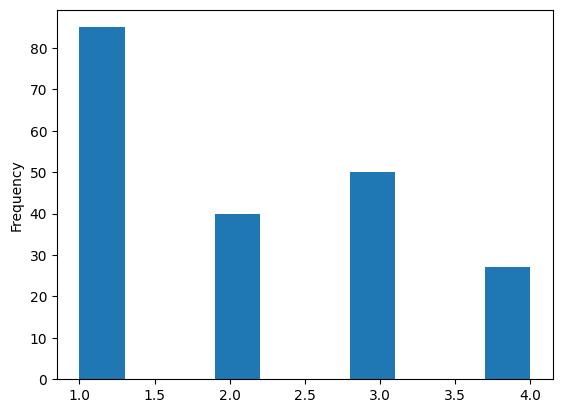

In [ ]:
#analyse univariée avec un plot
df_jeunes_hommes_reduit["jouets_genres_num"].plot(kind="hist")


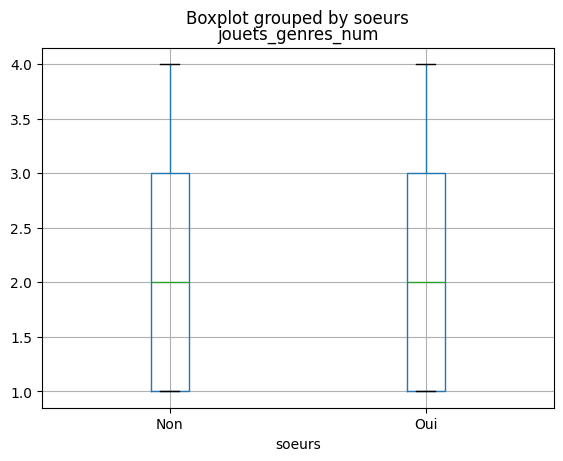

In [ ]:
#analyse bivariée avec des boites à moustache
df_jeunes_hommes_reduit.boxplot(column="jouets_genres_num", by="soeurs")
plt.show()




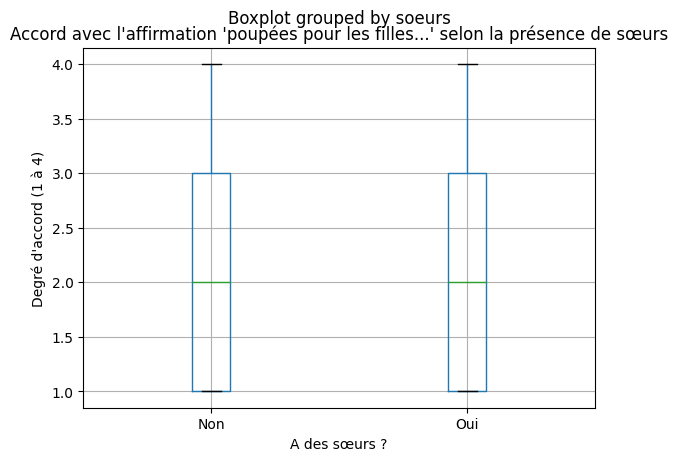

In [ ]:
#titre et légendes
df_jeunes_hommes_reduit.boxplot(column="jouets_genres_num", by="soeurs")

plt.title("Accord avec l'affirmation 'poupées pour les filles...' selon la présence de sœurs")
plt.xlabel("A des sœurs ?")
plt.ylabel("Degré d'accord (1 à 4)")

plt.show()

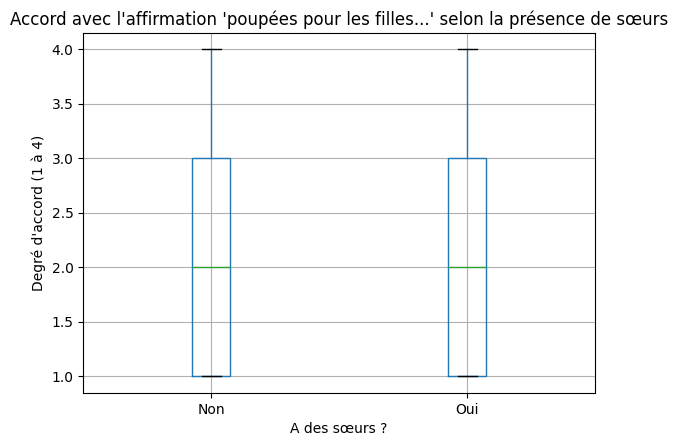

In [ ]:
#enlever le sur-titre bizzare
df_jeunes_hommes_reduit.boxplot(column="jouets_genres_num", by="soeurs")

plt.title("Accord avec l'affirmation 'poupées pour les filles...' selon la présence de sœurs")
plt.xlabel("A des sœurs ?")
plt.ylabel("Degré d'accord (1 à 4)")

plt.suptitle("")

plt.show()

Autres moyens de visualisation
- plot() : courbe
- plot.scatter() : nuage de point
- bar() : diagramme en batonn

<Axes: xlabel='jouets_genres_num'>

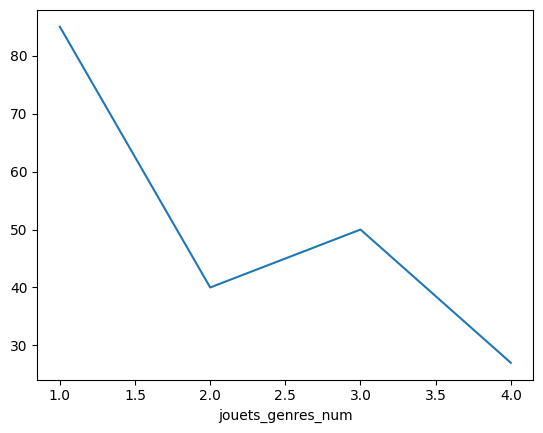

In [ ]:
graph_jouets = df_jeunes_hommes_reduit["jouets_genres_num"].value_counts().sort_index()

graph_jouets.plot()